# Round results: visual report

**Model-internal only.** Nothing in this notebook is calibrated to empirical
data (owner ruling, 2026-11-13); every number is read from a run archive on
disk and asserted against its expected shape before it is plotted.

One figure per headline round of the evidence ledger
(`AdmiralsLog/HANDOVER-2026-11-14.md`, section 1.3), drawn through the
project's house templates (CodeLearn `P_diagram_templates`, palette
`_shared/template_core.py`; the copy in `scripts/report_notebook/` is
byte-identical to the source, sha256 `6d4c0a89...`).

Per ADR-0002 the computation lives in `scripts/report_notebook/`
(`round_report_data.py`, `round_report_figures.py`); this notebook only
calls it.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

REPO = Path.cwd() if (Path.cwd() / "scripts").exists() else Path.cwd().parent
sys.path.insert(0, str(REPO / "scripts" / "report_notebook"))

import round_report_data as D
import round_report_figures as F

OUT = F.OUT
print("repo:", D.REPO)
print("figures ->", OUT.relative_to(D.REPO))

repo: /workspace/git/sciencemodels
figures -> output/report_notebook_v1


## Gross versus net

Attempted against verified, recomputed here rather than quoted: each loader
asserts the gross shape (cells, seeds) and returns only what is on disk.

In [2]:
manifest = D.manifest()
manifest

,round,gross,net
0,T1 sensitivity (post-audit arm),36 cells x 20 seeds = 720,720 runs in data/remeasure_v1/runs.csv (F1); 7...
1,T3 career flows (clean + noisy),9 + 9 cells x 20 seeds = 360,"9 + 9 cells, 180 + 180 seeds"
2,T4 welfare probe,40 cells x 20 seeds = 800,800 runs
3,W3-A prestige stock,36 cells x 20 seeds = 720,36 cells x 720 seeds
4,N1/N2 re-measure,"1,520 runs (76 cells)",720 T1 pairs + 800 W_v05 pairs (W arm excluded...


## F1 -- T1 sensitivity: the wedge opens under entry (post-audit arm)

Drawn from the **post-audit** re-measured arm (`data/remeasure_v1/runs.csv`,
720 T1 runs), not the pre-fix sweep, because the ideal-merit pairing audit
moved the levels this figure reports. Final prestige-ideal correlation falls
from positive to negative when entry turns on, and curiosity is protective
(the higher-curiosity line sits above the lower one at both entry rates).
The figure's source line carries the caption numbers: entry=0 mean +0.220,
entry=0.1 mean -0.144, 17/18 entry cells negative.

wrote output/report_notebook_v1/F1_sensitivity_entry_curiosity.png
caption: {'runs': 720, 'cells': 36, 'entry0_mean': 0.2200141212804271, 'entry01_mean': -0.14376371510455288, 'entry01_negative': 17, 'entry01_cells': 18, 'sign_flips': 0}


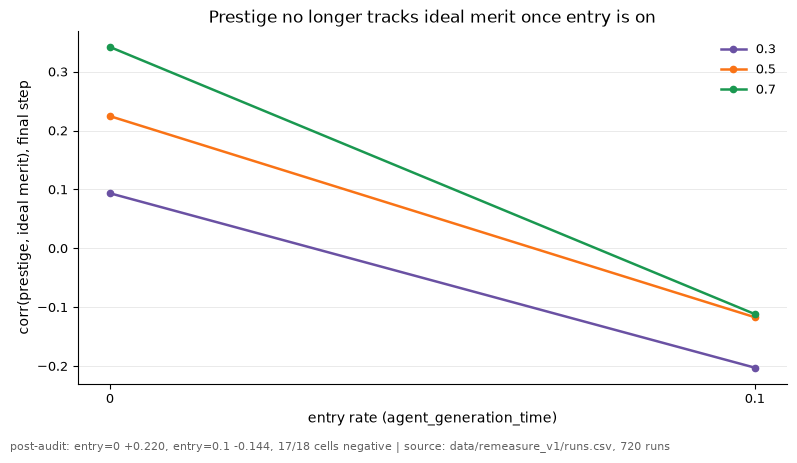

In [3]:
fig1, path1, cap1 = F.figure_sensitivity()
print("wrote", path1.relative_to(D.REPO))
print("caption:", {k: cap1[k] for k in
      ("runs", "cells", "entry0_mean", "entry01_mean",
       "entry01_negative", "entry01_cells", "sign_flips")})

## F2 -- T3 career flows: the gap never closes, on either terrain

Four series = landscape (clean, noisy) x statistic (final, late), each the
mean over the three curiosity levels. Both headline levels appear with their
statistic named, so the figure never compares one statistic on one line with
another on the next: clean final -0.71, noisy late -0.52. The gap is
everywhere negative.

wrote output/report_notebook_v1/F2_career_flows_gap_ratio.png


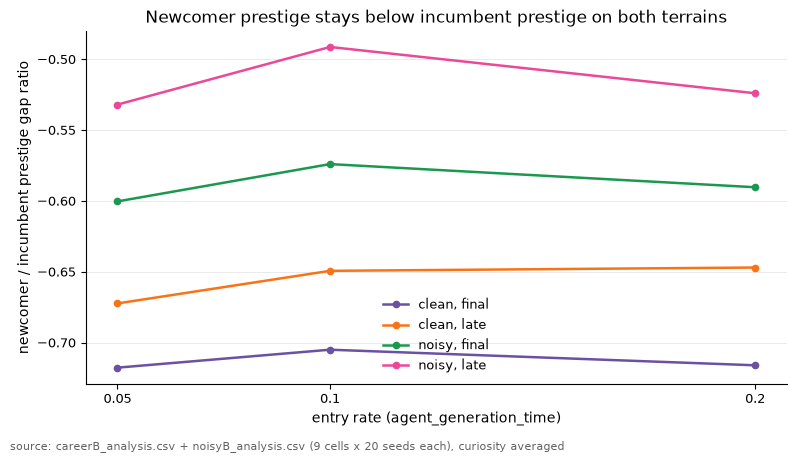

In [4]:
fig2, path2 = F.figure_career_flows()
print("wrote", path2.relative_to(D.REPO))

## F2b -- the slow-entry decoupling gradient

Final prestige-ideal correlation by entry rate and terrain. The most negative
correlation sits at the LOWEST entry rate on both terrains (clean -0.133 at
g=0.05 vs -0.025 at g=0.20; noisy -0.227 vs -0.112): slow entry lets founder
hierarchies harden before advisees arrive.

wrote output/report_notebook_v1/F2b_career_flows_noisy_vs_clean.png


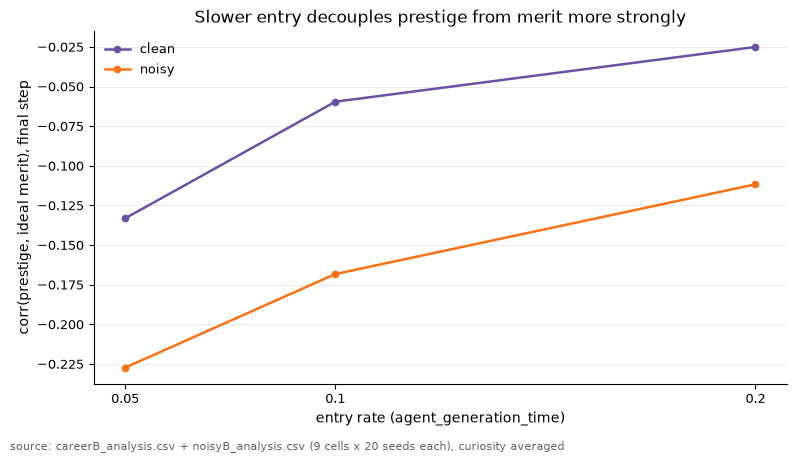

In [5]:
fig2b, path2b = F.figure_career_flows_ideal_corr()
print("wrote", path2b.relative_to(D.REPO))

## F3 -- T4 welfare probe: the price of visibility pressure

Loss rises steeply in the visibility weight along all four entry x legibility
series; the on/off reward toggle moves it by at most the amount printed in
the title, so the weight axis is the live lever. Means over the toggle.

wrote output/report_notebook_v1/F3_welfare_loss_vs_visibility_weight.png


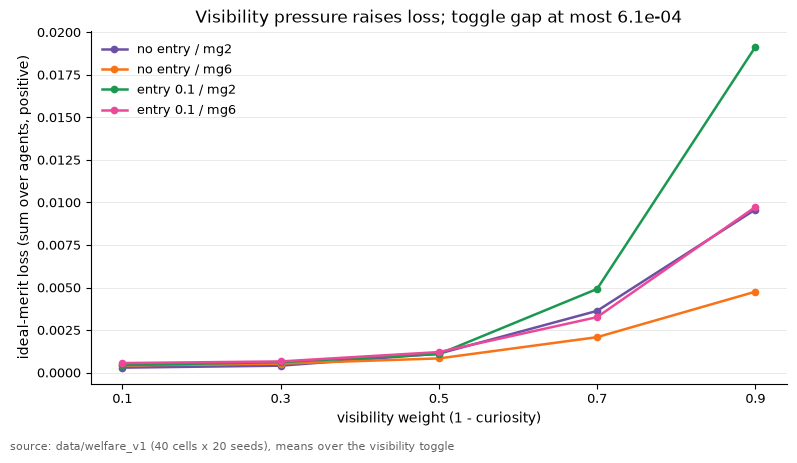

In [6]:
fig3, path3 = F.figure_welfare()
print("wrote", path3.relative_to(D.REPO))

## F4 -- W3-A prestige stock: how fast, not where

Entry-on cells only (the entry-off cells are bit-identical across stocks, so
they would draw three copies of the same bar). The three stocks move the
terminal wedge only marginally within every cell.

wrote output/report_notebook_v1/F4_prestige_stock_wedge_matrix.png


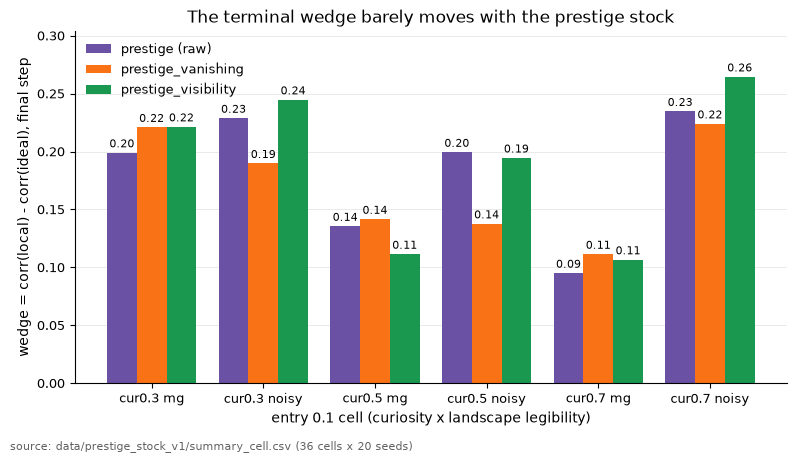

In [7]:
fig4, path4 = F.figure_prestige_stock()
print("wrote", path4.relative_to(D.REPO))

## F5 -- N1/N2 re-measure: what the pairing audit moved

Seed-matched pre-fix vs post-fix deltas on the T1 arm (720 pairs). The
ideal-side levels move, the local-side and top-10% reporters are untouched
(point estimates exactly 0), which is what makes the moved numbers
attributable to the pairing fix alone.

Two measurement facts discovered while building this figure, both asserted in
code rather than assumed:

1. **The welfare arm of the re-measure is excluded.** It was re-run at
   `vanishing_factor_for_prestige = 0.9` against `0.5` in the original sweep,
   so that arm carries two changes at once and its delta is not attributable
   to the pairing fix. 800 + 800 rows inspected, 0 paired.
2. **`runs.csv` stores `wedge = c_ideal - c_local`**, the opposite sign to
   the pre-arm convention; both arms are recomputed from the components
   before differencing (the archive's convention is asserted, then
   overridden). Trusting the column would have reported a -0.206 wedge
   "movement" that is a pure sign flip.

A third arm is wired in and **conditional**: if
`data/remeasure_v1/w_v05_runs.csv` is banked by the re-measure round, its 800
welfare runs pair against the original v05 sweep (which ran at vanishing
0.5) and are drawn as a second, dodged arm in F5. The file is absent at this
build, so F5 shows T1 only and the counts below record that as a fact rather
than an omission.

wrote output/report_notebook_v1/F5_pairing_audit_paired_delta.png
  post_gross: 1520
  t1_paired_net: 720
  w_paired_net: 0
  w_excluded: W arm re-run at vanishing [np.float64(0.9)] against [np.float64(0.5)] in the original sweep -- two changes at once, delta not attributable to the pairing fix
  w_post_rows: 800
  w_pre_rows: 800
  wedge_sign: runs.csv stores c_ideal - c_local; both arms recomputed as c_local - c_ideal before differencing
  w_v05_file: data/remeasure_v1/w_v05_runs.csv
  w_v05_present: True
  w_v05_paired_net: 800


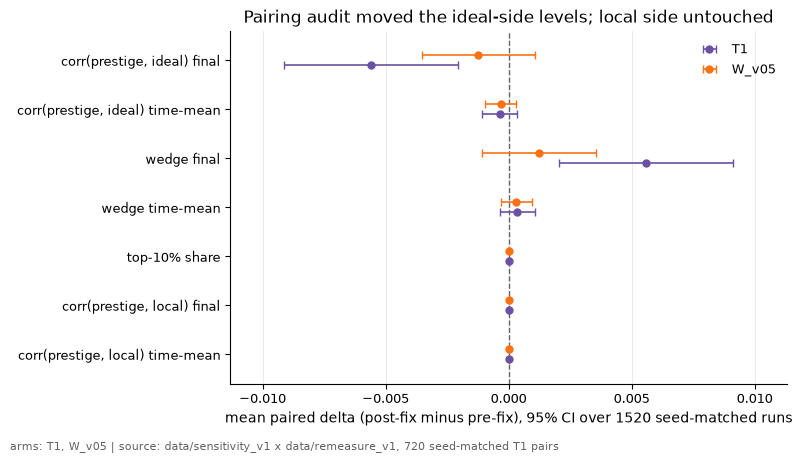

In [8]:
fig5, path5, rm_counts = F.figure_remeasure_delta()
print("wrote", path5.relative_to(D.REPO))
for k, v in rm_counts.items():
    print(f"  {k}: {v}")

## Artifacts and gate

Figures written by this notebook (each also carries its `_data.csv` where the
template provides one):

- `output/report_notebook_v1/F1_sensitivity_entry_curiosity.png`
- `output/report_notebook_v1/F2_career_flows_gap_ratio.png`
- `output/report_notebook_v1/F2b_career_flows_noisy_vs_clean.png`
- `output/report_notebook_v1/F3_welfare_loss_vs_visibility_weight.png`
- `output/report_notebook_v1/F4_prestige_stock_wedge_matrix.png`
- `output/report_notebook_v1/F5_pairing_audit_paired_delta.png` (+ `_data.csv`)

Sources are read-only: `data/remeasure_v1/`, `data/sensitivity_v1/`,
`data/career_flows_v1/`, `data/career_flows_noisy_v1/`, `data/welfare_v1/`,
`data/prestige_stock_v1/`.

Gate (tests/test_smoke.py), run before the first edit and after the last.

Report keys went 44 -> 56 since the previous build: the Path B dyadic layer
landed in the model between builds (off-mode bit-identity, logit/threshold
binding, knob validation). The bit-level anchors are unchanged
(mean_prestige = 0.025399760810316363; 4-arg Gaussian = 0.00550470835249002).

    canary run OK: 56 report keys, harvested_10_step=37.5, harvested_25_step=37.5
    same-seed rerun bit-identical OK
    newcomer run OK: 6 scientists after 20 steps
    4-arg Gaussian OK: np.float64(0.00550470835249002) (float64)
    append-mode header check OK: 3 lines = 1 header + 2 data rows
    ideal-merit pairing audit OK: A=0.0, C=0.0, B=-0.04999999999999999
    seed columns OK: agent_seed=1, landscape_seed=1
    WARNING: agent_generation_function '<lambda>' returned IDENTICAL draws for mu=0.1 and mu=0.9 on the same rng - the swept axis (initial_curiosity) is INERT.
    binding probe OK: constant generator flagged inert, identity binds
    entry_prestige_stock OK: validated, both alternate stocks run
    Path B off-mode bit-identity OK (anchor mean_prestige=np.float64(0.025399760810316363)); 0 dynamics keys differ
    Path B binding OK: logit lambda0=(np.int64(2), 1.024390243902439) lambda1=(np.int64(5), 2.1951219295129512)
    Path B binding OK: threshold lambda0=(np.int64(1), 1.0) lambda1=(np.int64(3), 2.048780487804878)
    Path B knob validation OK: all six knobs reject invalid values
    ALL SMOKE TESTS PASSED
    EXIT=0
